# Final Visualisation: E-commerce Sales Analysis - A Journey Through Trends and Insights

### Import Required Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load and Preprocess the Data

In [2]:
def load_and_preprocess_data(file_path):
    """
    Load the dataset and preprocess it

    """
    data = pd.read_csv(file_path)
    data['Date'] = pd.to_datetime(data['Date'], dayfirst=True)
    data['Year'] = data['Date'].dt.year
    data['Month'] = data['Date'].dt.month
    return data

# Load the dataset
file_path = 'Ecommerce_Sales_Prediction_Dataset.csv' 
data = load_and_preprocess_data(file_path)


### Stastical Table

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

def statistical_summary(data):
    """
    A statistical summary table for numeric columns
    """
    numeric_cols = ['Price', 'Discount', 'Marketing_Spend', 'Units_Sold']
    summary = data[numeric_cols].agg(['mean', 'median', 'std', 'min', 'max', 'sum']).transpose()
    summary.columns = ['Mean', 'Median', 'Std Dev', 'Min', 'Max', 'Sum']
    return summary


def save_table(dataframe, file_name):
    """
    Save the table in PNG format 
    """
    # Pastel colors for headers
    header_colors = ['#ffb3ba', '#ffdfba', '#ffffba', '#baffc9', '#bae1ff', '#d5a6bd']  # Soft pastel colors

    # Figure for the table
    fig, ax = plt.subplots(figsize=(14, 7))  # Adjust figure size
    ax.axis('off')  # Turn off axes

    # Create a table
    table_data = dataframe.reset_index()
    table = plt.table(
        cellText=table_data.values,
        colLabels=table_data.columns,
        cellLoc='center',
        loc='center'
    )

    # Styling
    for (row, col), cell in table.get_celld().items():
        if row == 0:  
            cell.set_facecolor(header_colors[col % len(header_colors)]) 
            cell.set_text_props(color='#2f2f2f', fontweight='bold') 
            cell.set_fontsize(12)
            cell.set_edgecolor('#e0e0e0')  
        elif row % 2 == 0:  
            cell.set_facecolor('#f9f9f9')  
            cell.set_edgecolor('#f0f0f0')  
        else:
            cell.set_facecolor('#ffffff')  
            cell.set_edgecolor('#f0f0f0')  
        cell.set_fontsize(10)
        cell.PAD = 0.15  

    # Adjust table scale
    table.scale(1.3, 1.3)

    # Transparent background
    plt.savefig(file_name, dpi=300, bbox_inches='tight', pad_inches=0.2, transparent=True)
    plt.close()


# Load your dataset
file_path = 'Ecommerce_Sales_Prediction_Dataset.csv' 
data = pd.read_csv(file_path)

# The statistical summary table
statistical_summary_df = statistical_summary(data)

# Save table as a PNG image
table_image_path = 'fancy_colored_table_transparent.png'
save_table(statistical_summary_df, table_image_path)

### Plot Monthly Sales Trend

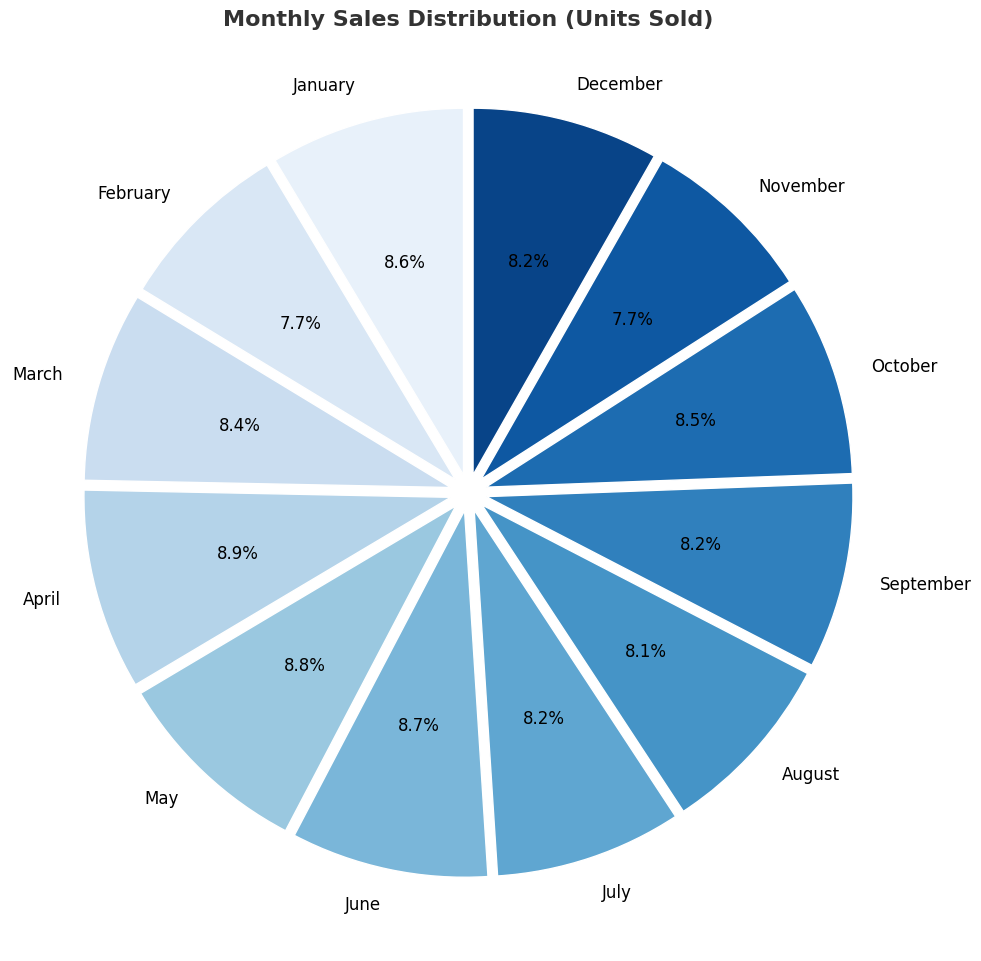

In [4]:
def plot_monthly_sales_pie(data):
    """
    Pie chart showing the distribution of Units Sold by Month
    """
    # The 'Month' column
    if 'Month' not in data.columns:
        data['Date'] = pd.to_datetime(data['Date'], errors='coerce')  
        data['Month'] = data['Date'].dt.month  
    
    # Group data by Month and calculate total Units Sold
    monthly_sales = data.groupby('Month')['Units_Sold'].sum().reset_index()
    
    # Month column is integer
    monthly_sales['Month'] = monthly_sales['Month'].astype(int)
    
    # Month labels
    month_labels = [
        'January', 'February', 'March', 'April', 'May', 'June', 
        'July', 'August', 'September', 'October', 'November', 'December'
    ]
    monthly_sales['Month_Name'] = monthly_sales['Month'].apply(lambda x: month_labels[x - 1])
    
    # Create a pie chart
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(aspect="equal"))
    wedges, texts, autotexts = ax.pie(
        monthly_sales['Units_Sold'],
        labels=monthly_sales['Month_Name'],
        autopct='%1.1f%%',  # Display percentages
        startangle=90,  # Start angle for alignment
        colors=sns.color_palette("Blues", len(monthly_sales['Month'])),  # Professional blue gradient palette
        explode=[0.05] * len(monthly_sales['Month']),  # Slightly explode all slices for clarity
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},  # Clean slice edges
        textprops={'fontsize': 12, 'color': 'black'}  # Text styling
    )
    
    # percentage text inside the slices
    for autotext in autotexts:
        autotext.set_color('black')
    
    # Add a title
    plt.title(
        'Monthly Sales Distribution (Units Sold)', 
        fontsize=16, fontweight='bold', color='#333333'
    )
    
    plt.tight_layout()
    plt.show()

# Call the function
plot_monthly_sales_pie(data)


### Plot Correlation Heatmap

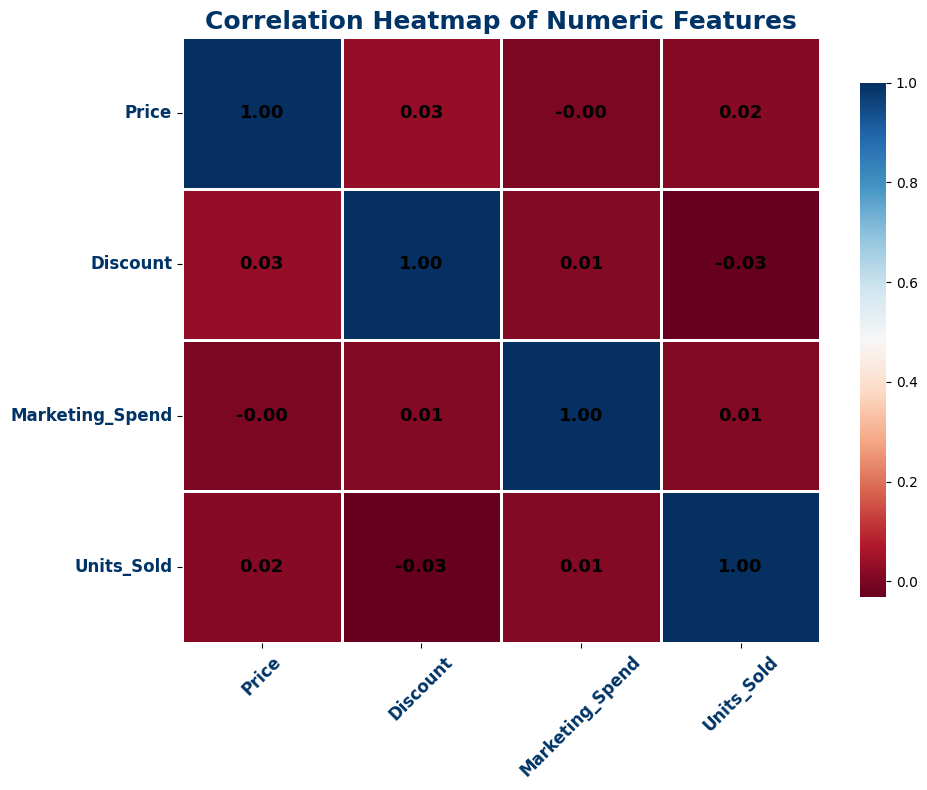

In [5]:
def plot_correlation_heatmap(data):
    """
    A heatmap showing correlations between numeric features
    with a bold 
    """
    correlation_matrix = data[['Price', 'Discount', 'Marketing_Spend', 'Units_Sold']].corr()
    
    # Plot the heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap='RdBu', 
        fmt='.2f',
        linewidths=1,
        linecolor='white',  
        cbar_kws={'shrink': 0.85, 'orientation': 'vertical'},  
        annot_kws={"size": 13, "fontweight": "bold", "color": "black"}  
    )
    plt.title('Correlation Heatmap of Numeric Features', fontsize=18, fontweight='bold', color='#003366')
    plt.xticks(fontsize=12, fontweight='bold', color='#003366', rotation=45)  # Navy blue axis labels
    plt.yticks(fontsize=12, fontweight='bold', color='#003366', rotation=0)
    plt.tight_layout()
    plt.show()

# Call the function
plot_correlation_heatmap(data)


### Plot Category-Wise Summary

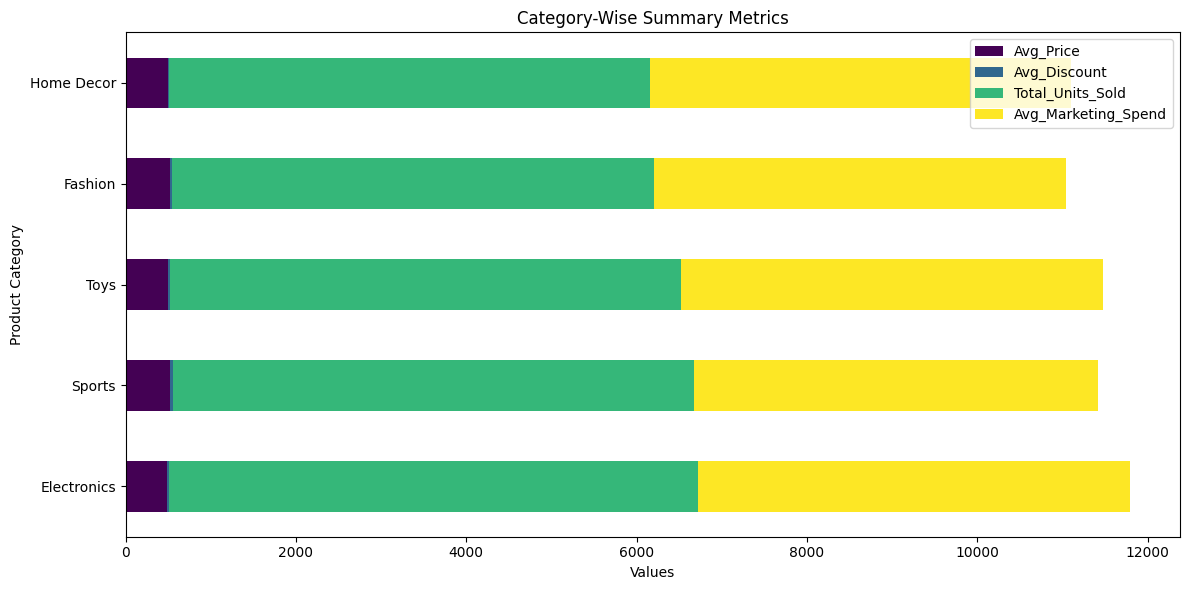

In [6]:
def plot_category_summary(data):
    """
    Category-wise summary metrics using a horizontal bar chart
    """
    # Group data by Product_Category
    category_summary = data.groupby('Product_Category').agg(
        Avg_Price=('Price', 'mean'),
        Avg_Discount=('Discount', 'mean'),
        Total_Units_Sold=('Units_Sold', 'sum'),
        Avg_Marketing_Spend=('Marketing_Spend', 'mean')
    ).sort_values(by='Total_Units_Sold', ascending=False)
    
    # Plot the summary
    category_summary.plot(kind='barh', figsize=(12, 6), stacked=True, colormap='viridis')
    plt.title('Category-Wise Summary Metrics')
    plt.xlabel('Values')
    plt.ylabel('Product Category')
    plt.tight_layout()
    plt.show()

# Call the function
plot_category_summary(data)

### Plot Marketing Spend vs Units Sold

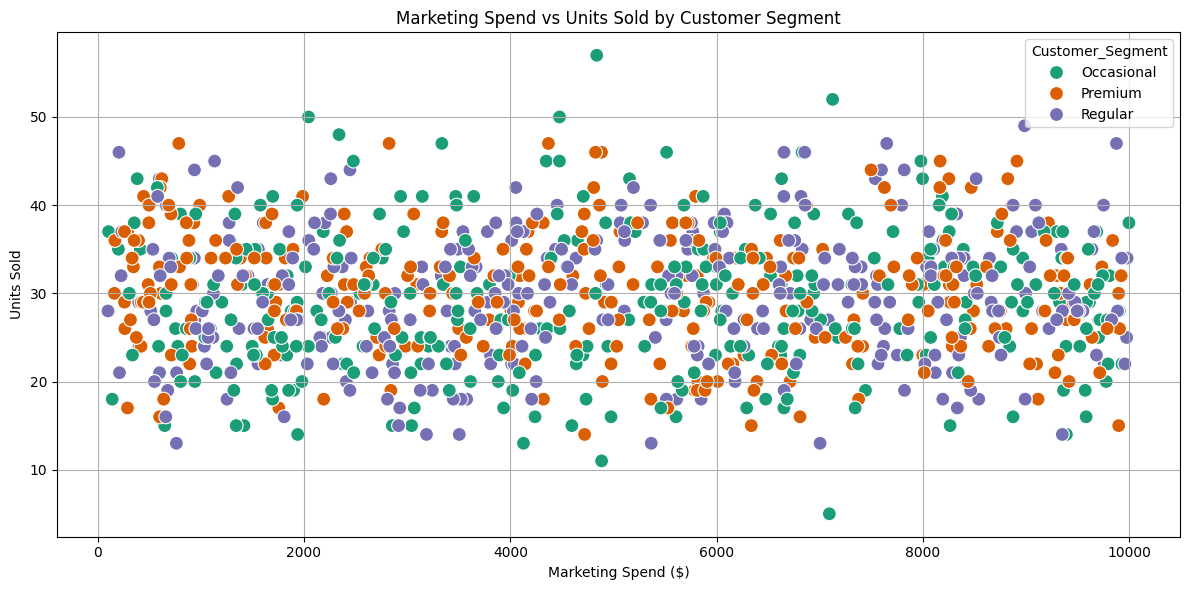

In [7]:
def plot_marketing_vs_sales(data):
    """
    The relationship between Marketing Spend and Units Sold
    """
    plt.figure(figsize=(12, 6))
    sns.scatterplot(
        data=data, x='Marketing_Spend', y='Units_Sold', hue='Customer_Segment', palette='Dark2', s=100
    )
    plt.title('Marketing Spend vs Units Sold by Customer Segment')
    plt.xlabel('Marketing Spend ($)')
    plt.ylabel('Units Sold')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Call the function
plot_marketing_vs_sales(data)
